In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
%matplotlib inline

In [ ]:
def f(x):
 return 3*x**2-4*x+5

In [ ]:
f(3.0)

20.0

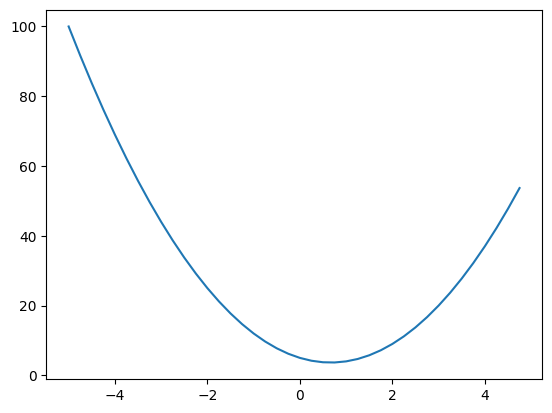

In [ ]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs,ys)

In [ ]:
def g(x):
  h=0.00001
  return (f(x+h)-f(x))/h
g(3.0)

14.00003000000538

In [ ]:
class Value:

  def __init__(self,data,_children=(), _op = '',label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda:None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __add__(self,other):
    out =  Value(self.data + other.data , (self,other), _op='+')
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0*out.grad
    out._backward = _backward
    return out

  def __mul__(self,other):
    other = other if isinstance(other,Value) else Value(other)
    out = Value(self.data * other.data , (self,other), _op='*')
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
    return out

  def __pow__(self,other):
    assert isinstance(other, (int,float))
    out = Value(self.data**other, (self,), _op = '^')
    def _backward():
      self.grad += other * (self.data**(other-1)) * out.grad
    out._backward = _backward
    return out

  def __rmul__(self,other):
    return self * other

  def __neg__(self):
    return self * (-1)

  def __sub__(self, other):
    return self + (-other)

  def exp(self):
    out = Value(math.exp(self.data), (self,), _op = 'exp')
    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def __truediv__(self,other):
    return self * other**(-1)

  def tanh(self):
    x = self.data
    t = (math.exp(x)-math.exp(-x))/(math.exp(x)+math.exp(-x))
    out = Value(t,(self,), 'tanh')
    def _backward():
      self.grad += (1 - t**2)*out.grad
    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    self.grad = 1.0
    build_topo(self)
    for node in reversed(topo):
      node._backward()

  def __repr__(self):
    return f"Value(data = {self.data})"

In [ ]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
h=0.001
a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10.0,label='c')
e = a*b;e.label='e'
d = e+c;e.label='d'
f = Value(-2.0,label='f')
L = d*f;L.label='L'
L1 = L.data

a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10.0,label='c')
e = a*b;e.label='e'
d = e+c;d.label='d'
f = Value(-2.0,label='f')
L = d*f;L.label='L'
L2 = L.data

In [ ]:
L.grad = 1
d.grad = f.data
f.grad = d.data
e.grad = d.grad * 1
c.grad = d.grad * 1
a.grad = d.grad * b.data
b.grad = d.grad * a.data

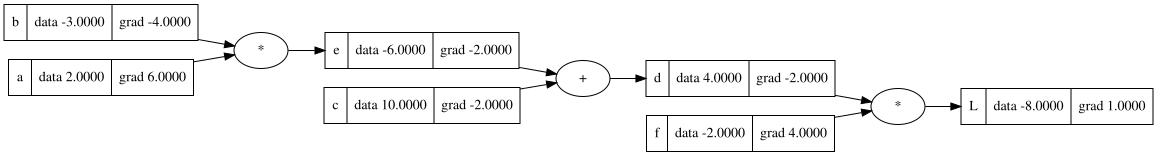

In [ ]:
draw_dot(L)

Text(0.5, 1.0, 'Graph of tanh')

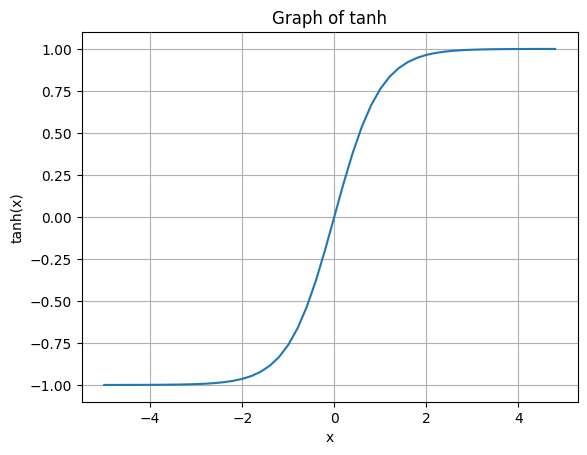

In [ ]:
plt.plot(np.arange(-5,5,0.2),np.tanh(np.arange(-5,5,0.2)))
plt.grid()
plt.xlabel("x")
plt.ylabel("tanh(x)")
plt.title("Graph of tanh")

In [ ]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
f = x1w1x2w2 + b; f.label = "f"
o = f.tanh(); o.label = "o"

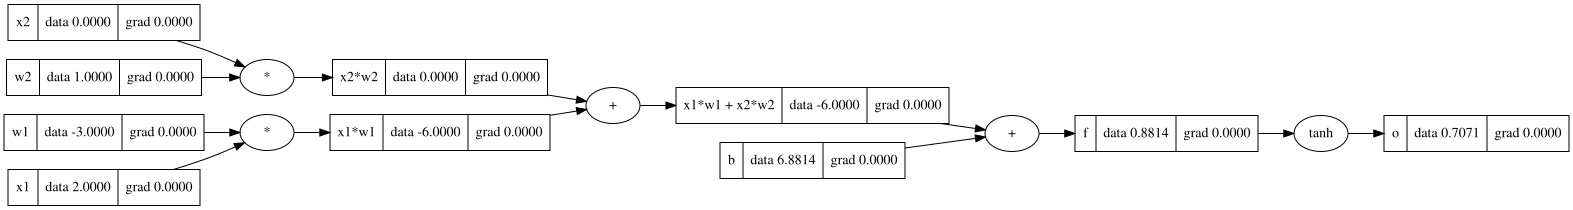

In [ ]:
draw_dot(o)

In [ ]:
o.backward()

In [ ]:
o.grad = 1
o._backward()
f._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
x1._backward()
x2._backward()
w1._backward()
w2._backward()
b._backward()

# Topological Sort
Topological sorting for Directed Acyclic Graph (DAG) is a linear ordering of vertices such that for every directed edge u→v, vertex u comes before v in the ordering. There may be several topological orderings for a graph.

Applies only to DAGs (Directed Acyclic Graphs), and is not possible for cyclic or undirected graphs.
It represents dependency ordering between vertices which is different from normal DFS or BFS traversals.
Used in problems like task scheduling, build order, course prerequisite ordering, etc.

**Here we have to do Topological sorting as we want the backpropagation to
happen in just one step where are the previous steps of the backward movement is completed and hence the thing will happen by calling just one step for a singular node. So if i am going to do the backpropagation of Node O then the entire children family of the Node O will be linearly arranged first by the topo sort and then the backpropagation can be completed in one step**

In [ ]:
##f.grad = 1 - o.data**2

In [ ]:
##x1w1x2w2.grad = 0.5
##b.grad = 0.5

In [ ]:
##x2w2.grad = 0.5
##x1w1.grad = 0.5

In [ ]:
##w1.grad = x1.data * x1w1.grad
##x1.grad = w1.data * x1w1.grad

In [ ]:
##x2.grad = w2.data * x2w2.grad
##w2.grad = x2.data * x2w2.grad

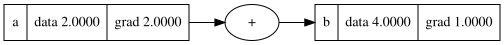

In [ ]:
a = Value(2.0,label='a')
b = a+a; b.label = 'b'
b.backward()
draw_dot(b)

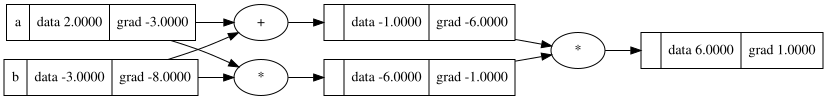

In [ ]:
a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = a+b
d = a*b
e = c*d
e.backward()
draw_dot(e)

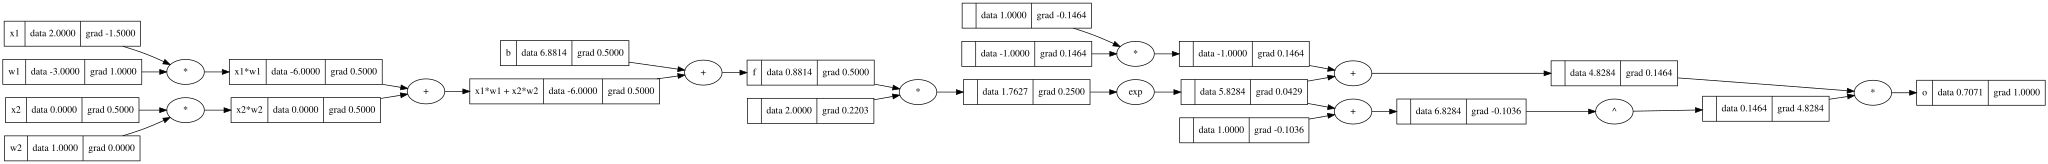

In [ ]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
f = x1w1x2w2 + b; f.label = "f"
e = (Value(2.0)*f).exp()
o = (e - Value(1.0))/(e + Value(1.0)); o.label = "o"
o.backward()
draw_dot(o)

In [ ]:
import torch

In [ ]:
x1 = torch.tensor([2.0]).double(); x1.requires_grad=True
x2 = torch.tensor([0.0]).double(); x2.requires_grad=True
w1 = torch.tensor([-3.0]).double(); w1.requires_grad=True
w2 = torch.tensor([1.0]).double(); w2.requires_grad=True
b = torch.tensor([6.8813735870195432]).double(); b.requires_grad=True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
o.backward()
print('---')
print(x1.grad.item())
print(x2.grad.item())
print(w1.grad.item())
print(w2.grad.item())

---
-1.5000003851533106
0.5000001283844369
1.0000002567688737
0.0


In [ ]:
import random

class Neuron:
  def __init__(self,nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  def __call__(self,x):
    act = sum((wi*xi for wi,xi in zip(self.w,x)),self.b)
    out = act.tanh()
    return out
  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self,nin,nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  def __call__(self,x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]
class MLP:
  def __init__(self,nin,nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
  def __call__(self,x):
    for layer in self.layers:
      x = layer(x)
    return x
  def parameters(self):
    return [p for Layer in self.layers for p in Layer.parameters()]



In [ ]:
x = [Value(2.0),Value(3.0),Value(-1.0)]
n = MLP(3,[4,4,1])
print(n(x))

Value(data = -0.8679771195640853)


In [ ]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data = -0.8679771195640853),
 Value(data = -0.8629752630737493),
 Value(data = -0.7786848576068989),
 Value(data = -0.8371747939669888)]

In [ ]:
for k in range(10000):
  ypred = [n(x) for x in xs]
  loss = sum((((Value(ygt) - yp)**2) for ygt, yp in zip(ys,ypred)),Value(0))

  for p in n.parameters():
    p.grad = 0
  loss.backward()

  for p in n.parameters():
    p.data += -0.2*p.grad
  print(k,loss.data)

Streaming output truncated to the last 5000 lines.
5000 2.013381718135444e-05
5001 2.0130384392622118e-05
5002 2.0126952762361868e-05
5003 2.012352228999192e-05
5004 2.012009297492685e-05
5005 2.011666481658605e-05
5006 2.0113237814386397e-05
5007 2.0109811967740924e-05
5008 2.0106387276075043e-05
5009 2.0102963738799585e-05
5010 2.0099541355338106e-05
5011 2.0096120125108617e-05
5012 2.009270004753315e-05
5013 2.008928112202551e-05
5014 2.0085863348015137e-05
5015 2.008244672491399e-05
5016 2.0079031252147014e-05
5017 2.0075616929135033e-05
5018 2.0072203755301633e-05
5019 2.006879173006751e-05
5020 2.006538085285603e-05
5021 2.0061971123088408e-05
5022 2.005856254019117e-05
5023 2.005515510358432e-05
5024 2.0051748812695707e-05
5025 2.004834366694919e-05
5026 2.004493966576613e-05
5027 2.0041536808578136e-05
5028 2.0038135094805843e-05
5029 2.003473452387988e-05
5030 2.0031335095222365e-05
5031 2.0027936808259997e-05
5032 2.0024539662424455e-05
5033 2.0021143657140454e-05
5034 2.0017

In [ ]:
ypred

[Value(data = 0.9979681397628507),
 Value(data = -0.9985854323512943),
 Value(data = -0.9979808333208717),
 Value(data = 0.9992070301473829)]

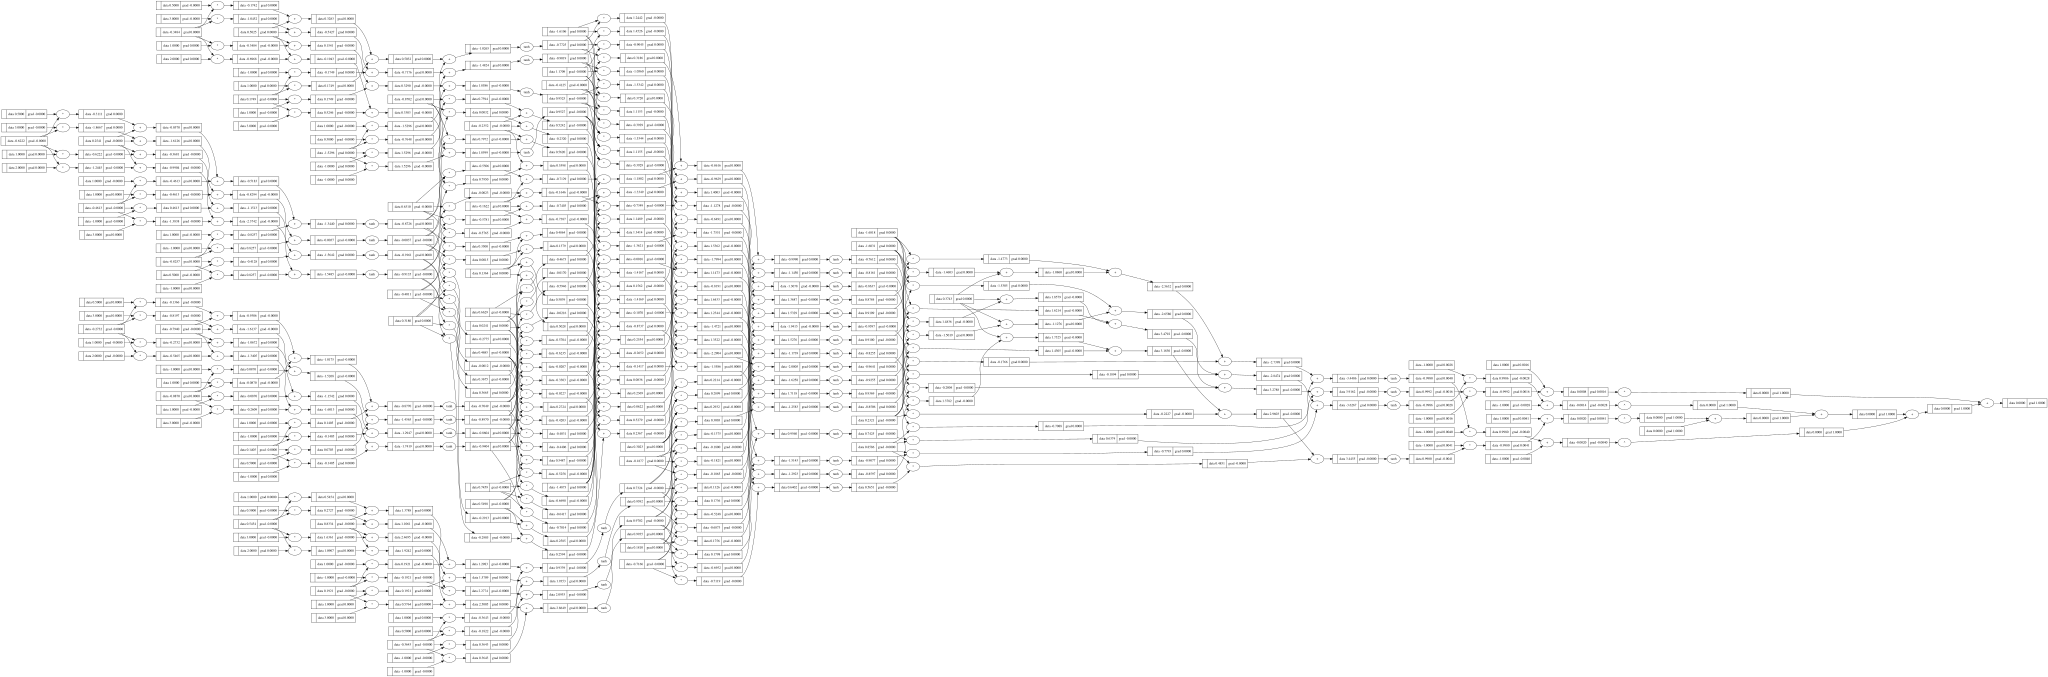

In [ ]:
draw_dot(loss)